In [6]:

import pandas as pd

df = pd.read_csv("german_credit_risk_new.csv")

# 1. Dataset dimensions
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

# 2. Column names
print("\nColumn names:")
print(df.columns.tolist())


# 5. Target class distribution
if "Risk" in df.columns:
    print("\nCredit risk distribution:")
    print(df["Risk"].value_counts())

# 6. Data types
print("\nColumn data types:")
print(df.dtypes)



Total rows: 1000
Total columns: 11

Column names:
['Unnamed: 0', 'Age', 'Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account', 'Credit amount', 'Duration', 'Purpose', 'Risk']

Credit risk distribution:
Risk
good    700
bad     300
Name: count, dtype: int64

Column data types:
Unnamed: 0          int64
Age                 int64
Sex                   str
Job                 int64
Housing               str
Saving accounts       str
Checking account      str
Credit amount       int64
Duration            int64
Purpose               str
Risk                  str
dtype: object


In [7]:

# Remove the unnecessary CSV index column
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nMissing values:")
print(df.isnull().sum())

print("\nTarget column available:", "Risk" in df.columns)

if "Risk" not in df.columns:
    print("\nCannot train a supervised risk classifier yet.")
    print("We need the actual good/bad credit-risk labels.")


Rows: 1000
Columns: 10

Missing values:
Age                   0
Sex                   0
Job                   0
Housing               0
Saving accounts     183
Checking account    394
Credit amount         0
Duration              0
Purpose               0
Risk                  0
dtype: int64

Target column available: True


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [9]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

X = df.drop("Risk", axis=1)
y = df["Risk"]

numeric_columns = X.select_dtypes(include=["int64", "float64"]).columns
categorical_columns = X.select_dtypes(include=["object", "str", "category"]).columns

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

print("Numeric features:", list(numeric_columns))
print("Categorical features:", list(categorical_columns))
print("Target classes:", sorted(y.unique()))

Numeric features: ['Age', 'Job', 'Credit amount', 'Duration']
Categorical features: ['Sex', 'Housing', 'Saving accounts', 'Checking account', 'Purpose']
Target classes: ['bad', 'good']


In [10]:
import math

def entropy(labels):
    counts = labels.value_counts()
    total = len(labels)

    result = 0

    for count in counts:
        p = count / total
        result -= p * math.log2(p)

    return result


def gini_impurity(labels):
    counts = labels.value_counts()
    total = len(labels)

    result = 1

    for count in counts:
        p = count / total
        result -= p ** 2

    return result


print("Entropy of Risk:", entropy(y))
print("Gini Impurity of Risk:", gini_impurity(y))

Entropy of Risk: 0.8812908992306927
Gini Impurity of Risk: 0.42000000000000004


In [11]:
def calculate_split_metrics(data, feature, target):
    parent_entropy = entropy(data[target])
    parent_gini = gini_impurity(data[target])

    weighted_entropy = 0
    weighted_gini = 0

    for value in data[feature].unique():
        subset = data[data[feature] == value]
        weight = len(subset) / len(data)

        weighted_entropy += weight * entropy(subset[target])
        weighted_gini += weight * gini_impurity(subset[target])

    information_gain = parent_entropy - weighted_entropy
    gini_reduction = parent_gini - weighted_gini

    return information_gain, gini_reduction


ig, gr = calculate_split_metrics(df, "Housing", "Risk")

print("Parent Entropy:", round(entropy(y), 4))
print("Parent Gini:", round(gini_impurity(y), 4))
print("Information Gain for Housing:", round(ig, 4))
print("Gini Reduction for Housing:", round(gr, 4))

Parent Entropy: 0.8813
Parent Gini: 0.42
Information Gain for Housing: 0.0128
Gini Reduction for Housing: 0.0076


In [12]:
results = []

for feature in categorical_columns:
    if feature == "Risk":
        continue

    ig, gr = calculate_split_metrics(df, feature, "Risk")

    results.append({
        "Feature": feature,
        "Information Gain": ig,
        "Gini Reduction": gr
    })

results_df = pd.DataFrame(results)
print(results_df.sort_values("Information Gain", ascending=False).round(4))

            Feature  Information Gain  Gini Reduction
3  Checking account            0.2996          0.1332
2   Saving accounts            0.1505          0.0680
1           Housing            0.0128          0.0076
4           Purpose            0.0100          0.0057
0               Sex            0.0040          0.0024


In [13]:
def best_split(data, target, criterion="entropy"):
    best_gain = -1
    best_feature = None
    best_value = None

    parent_impurity = (
        entropy(data[target])
        if criterion == "entropy"
        else gini_impurity(data[target])
    )

    for feature in data.columns:
        if feature == target:
            continue

        values = data[feature].dropna().unique()

        if pd.api.types.is_numeric_dtype(data[feature]):
            values = sorted(values)
            candidates = [
                (values[i] + values[i + 1]) / 2
                for i in range(len(values) - 1)
            ]
            split_type = "numeric"
        else:
            candidates = values
            split_type = "categorical"

        for value in candidates:
            if split_type == "numeric":
                left = data[data[feature] <= value]
                right = data[data[feature] > value]
            else:
                left = data[data[feature] == value]
                right = data[data[feature] != value]

            if len(left) == 0 or len(right) == 0:
                continue

            left_impurity = (
                entropy(left[target])
                if criterion == "entropy"
                else gini_impurity(left[target])
            )
            right_impurity = (
                entropy(right[target])
                if criterion == "entropy"
                else gini_impurity(right[target])
            )

            weighted_impurity = (
                len(left) / len(data) * left_impurity
                + len(right) / len(data) * right_impurity
            )

            gain = parent_impurity - weighted_impurity

            if gain > best_gain:
                best_gain = gain
                best_feature = feature
                best_value = value
                best_type = split_type

    return best_feature, best_value, best_gain, best_type

In [14]:
from collections import Counter

def build_tree(data, target, depth=0, max_depth=3):
    labels = data[target]

    # Stop if all rows have the same class
    if labels.nunique() == 1:
        return {"prediction": labels.iloc[0]}

    # Stop when maximum depth is reached
    if depth >= max_depth:
        return {"prediction": labels.mode()[0]}

    feature, value, gain, split_type = best_split(
        data.drop(columns=[target]),
        target,
        criterion="entropy"
    ) if False else (None, None, None, None)

In [15]:
def build_tree(data, target, depth=0, max_depth=3):
    labels = data[target]

    if labels.nunique() == 1:
        return {"prediction": labels.iloc[0]}

    if depth >= max_depth:
        return {"prediction": labels.mode()[0]}

    feature, value, gain, split_type = best_split(
        data, target, criterion="entropy"
    )

    if feature is None or gain <= 0:
        return {"prediction": labels.mode()[0]}

    if split_type == "numeric":
        left = data[data[feature] <= value]
        right = data[data[feature] > value]
    else:
        left = data[data[feature] == value]
        right = data[data[feature] != value]

    return {
        "feature": feature,
        "value": value,
        "split_type": split_type,
        "gain": gain,
        "left": build_tree(left, target, depth + 1, max_depth),
        "right": build_tree(right, target, depth + 1, max_depth)
    }

In [16]:
small_df = df[
    ["Age", "Job", "Credit amount", "Duration", "Risk"]
].copy()

small_df = small_df.dropna()

small_tree = build_tree(
    small_df,
    target="Risk",
    max_depth=3
)

print(small_tree)

{'feature': 'Duration', 'value': np.float64(15.5), 'split_type': 'numeric', 'gain': 0.023329147015652696, 'left': {'feature': 'Credit amount', 'value': np.float64(7668.5), 'split_type': 'numeric', 'gain': 0.021364382424935435, 'left': {'feature': 'Age', 'value': np.float64(34.5), 'split_type': 'numeric', 'gain': 0.018711370848969344, 'left': {'prediction': 'good'}, 'right': {'prediction': 'good'}}, 'right': {'prediction': 'bad'}}, 'right': {'feature': 'Duration', 'value': np.float64(43.5), 'split_type': 'numeric', 'gain': 0.016820491334190946, 'left': {'feature': 'Credit amount', 'value': np.float64(11191.0), 'split_type': 'numeric', 'gain': 0.014706677184288863, 'left': {'prediction': 'good'}, 'right': {'prediction': 'bad'}}, 'right': {'feature': 'Age', 'value': np.float64(25.5), 'split_type': 'numeric', 'gain': 0.04500234616082088, 'left': {'prediction': 'bad'}, 'right': {'prediction': 'bad'}}}}


In [17]:
def predict_one(tree, sample):
    if "prediction" in tree:
        return tree["prediction"]

    feature = tree["feature"]
    value = tree["value"]

    if tree["split_type"] == "numeric":
        go_left = sample[feature] <= value
    else:
        go_left = sample[feature] == value

    if go_left:
        return predict_one(tree["left"], sample)

    return predict_one(tree["right"], sample)


sample = {
    "Age": 25,
    "Job": 2,
    "Credit amount": 3000,
    "Duration": 12
}

print("Predicted risk:", predict_one(small_tree, sample))

Predicted risk: good


In [20]:
samples = [
    {"Age": 25, "Job": 2, "Credit amount": 3000, "Duration": 12},
    {"Age": 50, "Job": 1, "Credit amount": 8000, "Duration": 36},
    {"Age": 35, "Job": 3, "Credit amount": 1500, "Duration": 6}
]

for i, sample in enumerate(samples, start=1):
    prediction = predict_one(small_tree, sample)
    print(f"Sample {i}: {sample}")
    print("Predicted Risk:", prediction)
    print()

Sample 1: {'Age': 25, 'Job': 2, 'Credit amount': 3000, 'Duration': 12}
Predicted Risk: good

Sample 2: {'Age': 50, 'Job': 1, 'Credit amount': 8000, 'Duration': 36}
Predicted Risk: good

Sample 3: {'Age': 35, 'Job': 3, 'Credit amount': 1500, 'Duration': 6}
Predicted Risk: good



In [19]:
X = df.drop("Risk", axis=1)
y = df["Risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("\nTraining risk distribution:")
print(y_train.value_counts())

Training rows: 800
Testing rows: 200

Training risk distribution:
Risk
good    560
bad     240
Name: count, dtype: int64


In [21]:
depths = [2, 4, 6, 10, None]

models = {}
results = []

for depth in depths:
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            criterion="gini",
            max_depth=depth,
            random_state=42
        ))
    ])

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    results.append({
        "Max Depth": str(depth),
        "Training Accuracy": accuracy_score(y_train, train_pred),
        "Testing Accuracy": accuracy_score(y_test, test_pred)
    })

    models[depth] = model

results_df = pd.DataFrame(results)
print(results_df.round(4))

  Max Depth  Training Accuracy  Testing Accuracy
0         2             0.7000             0.700
1         4             0.7638             0.685
2         6             0.8088             0.710
3        10             0.8975             0.685
4      None             1.0000             0.700


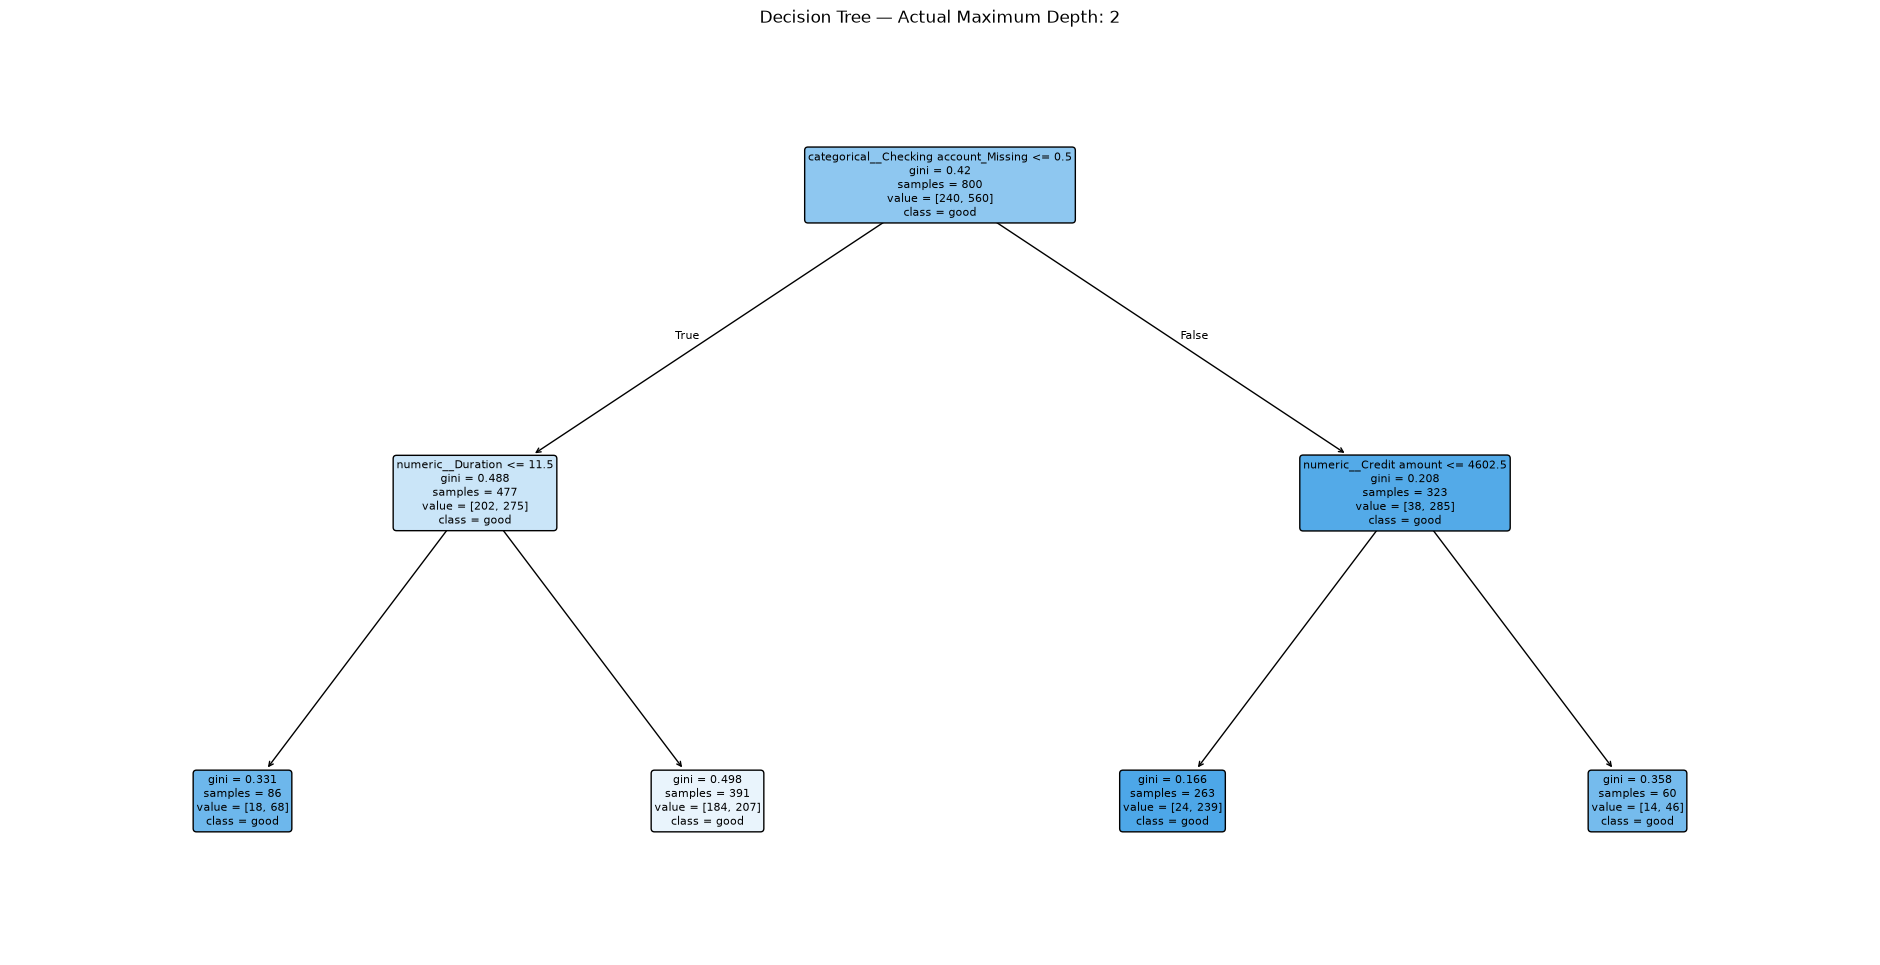

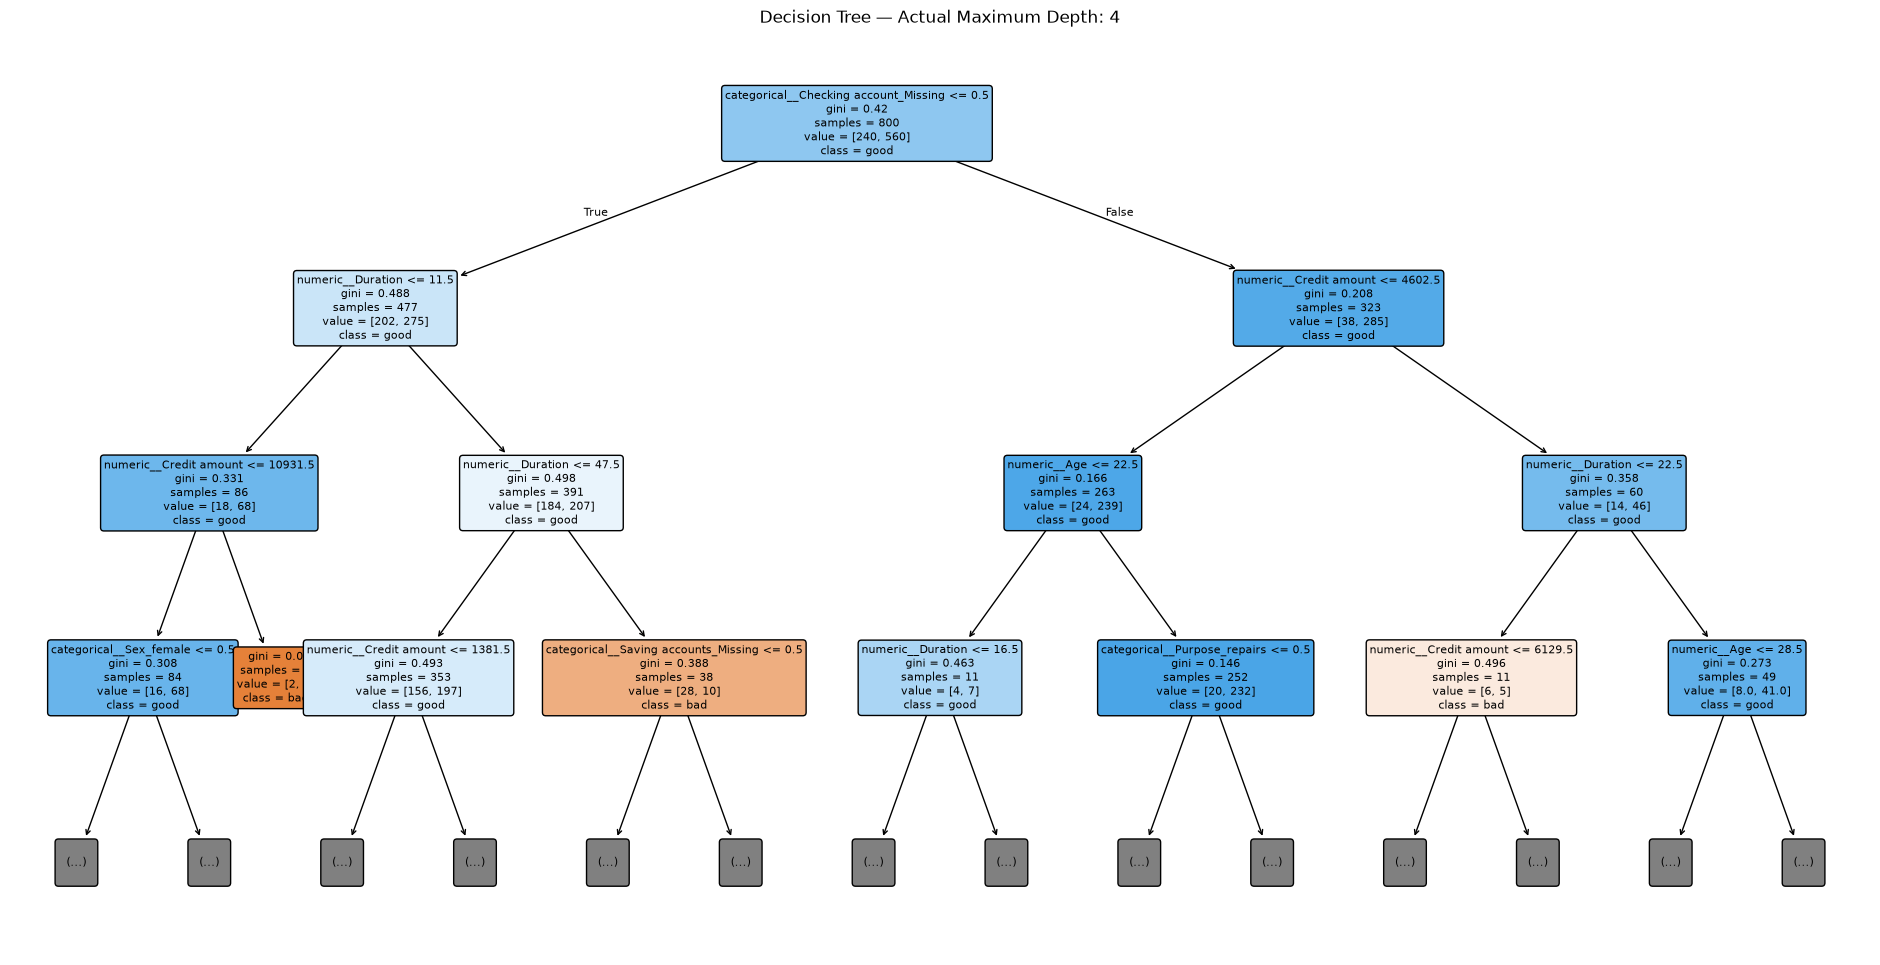

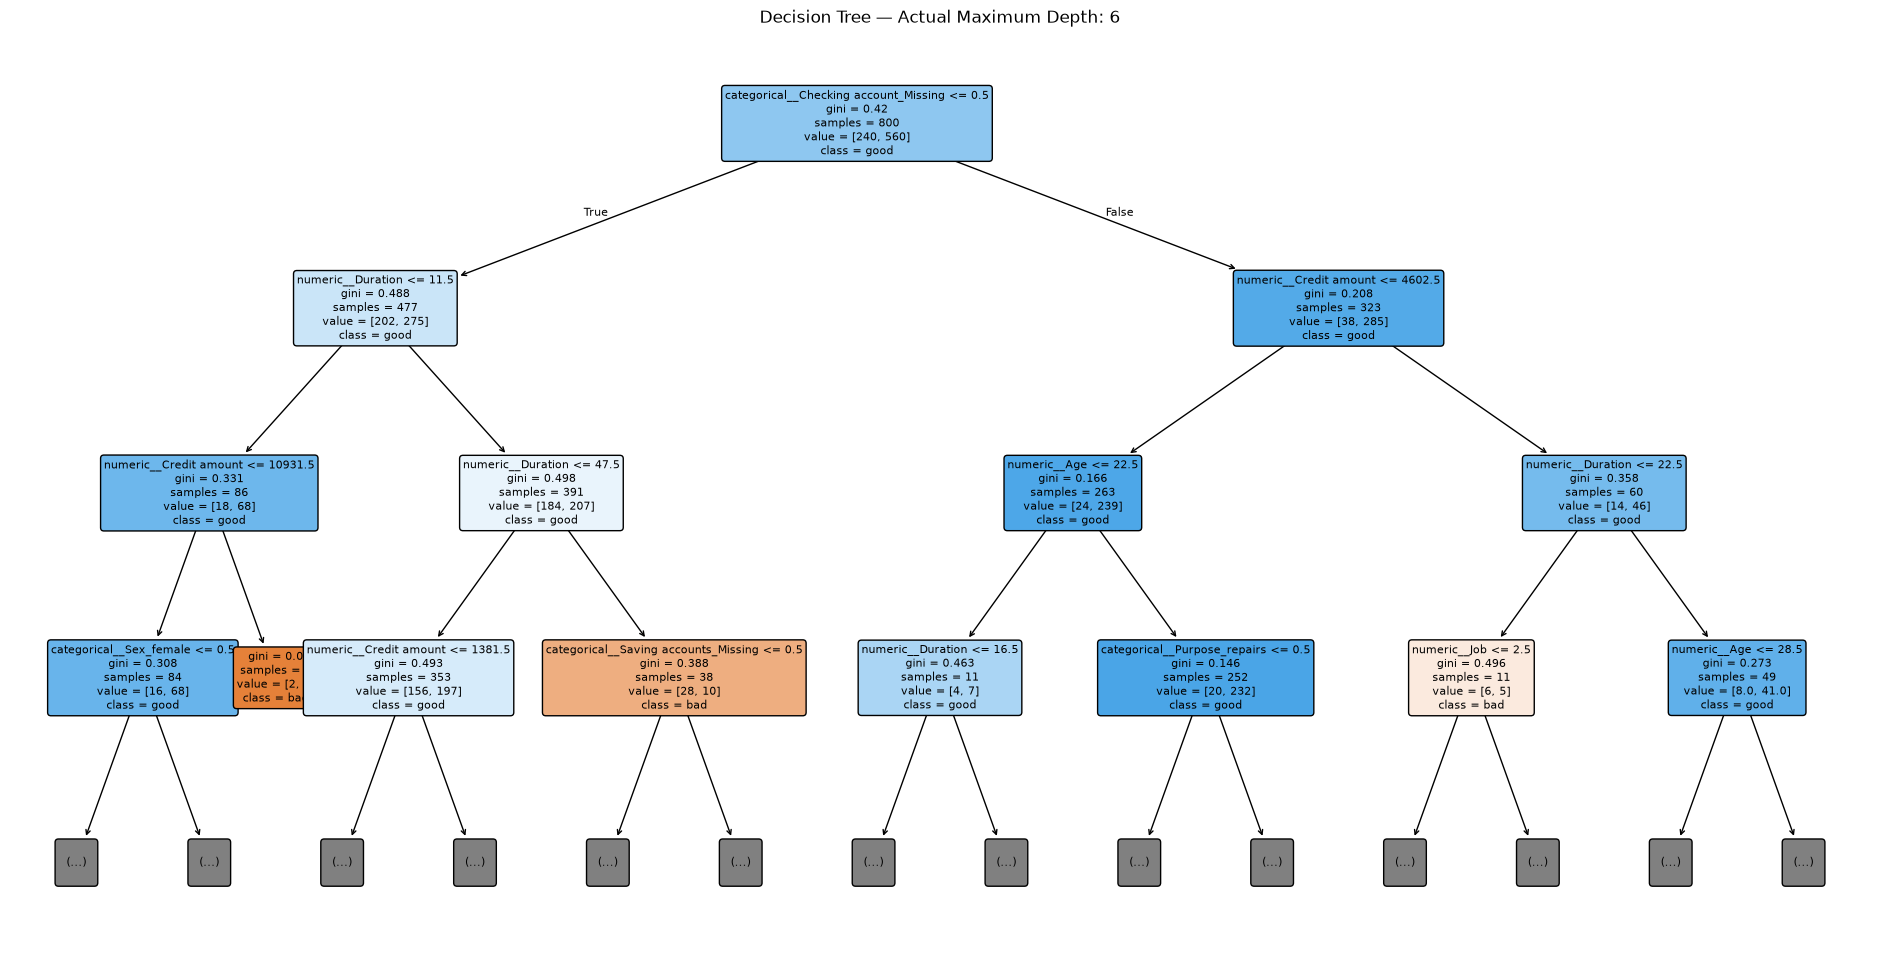

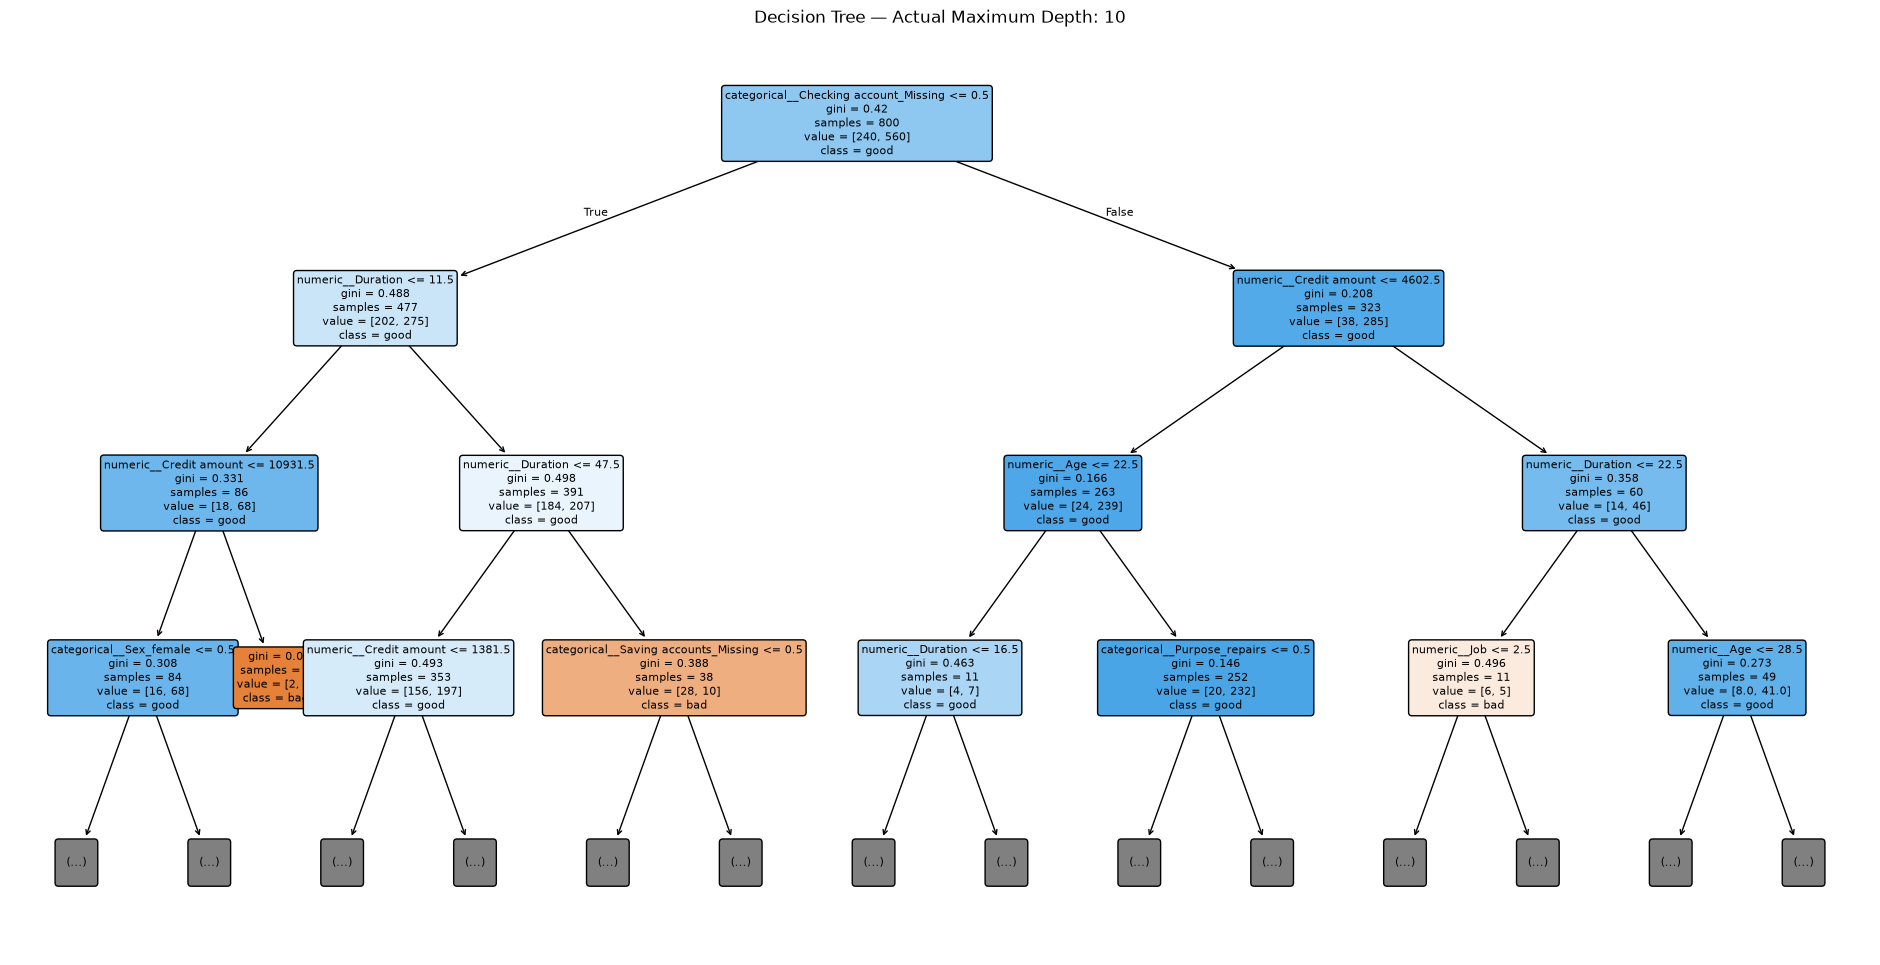

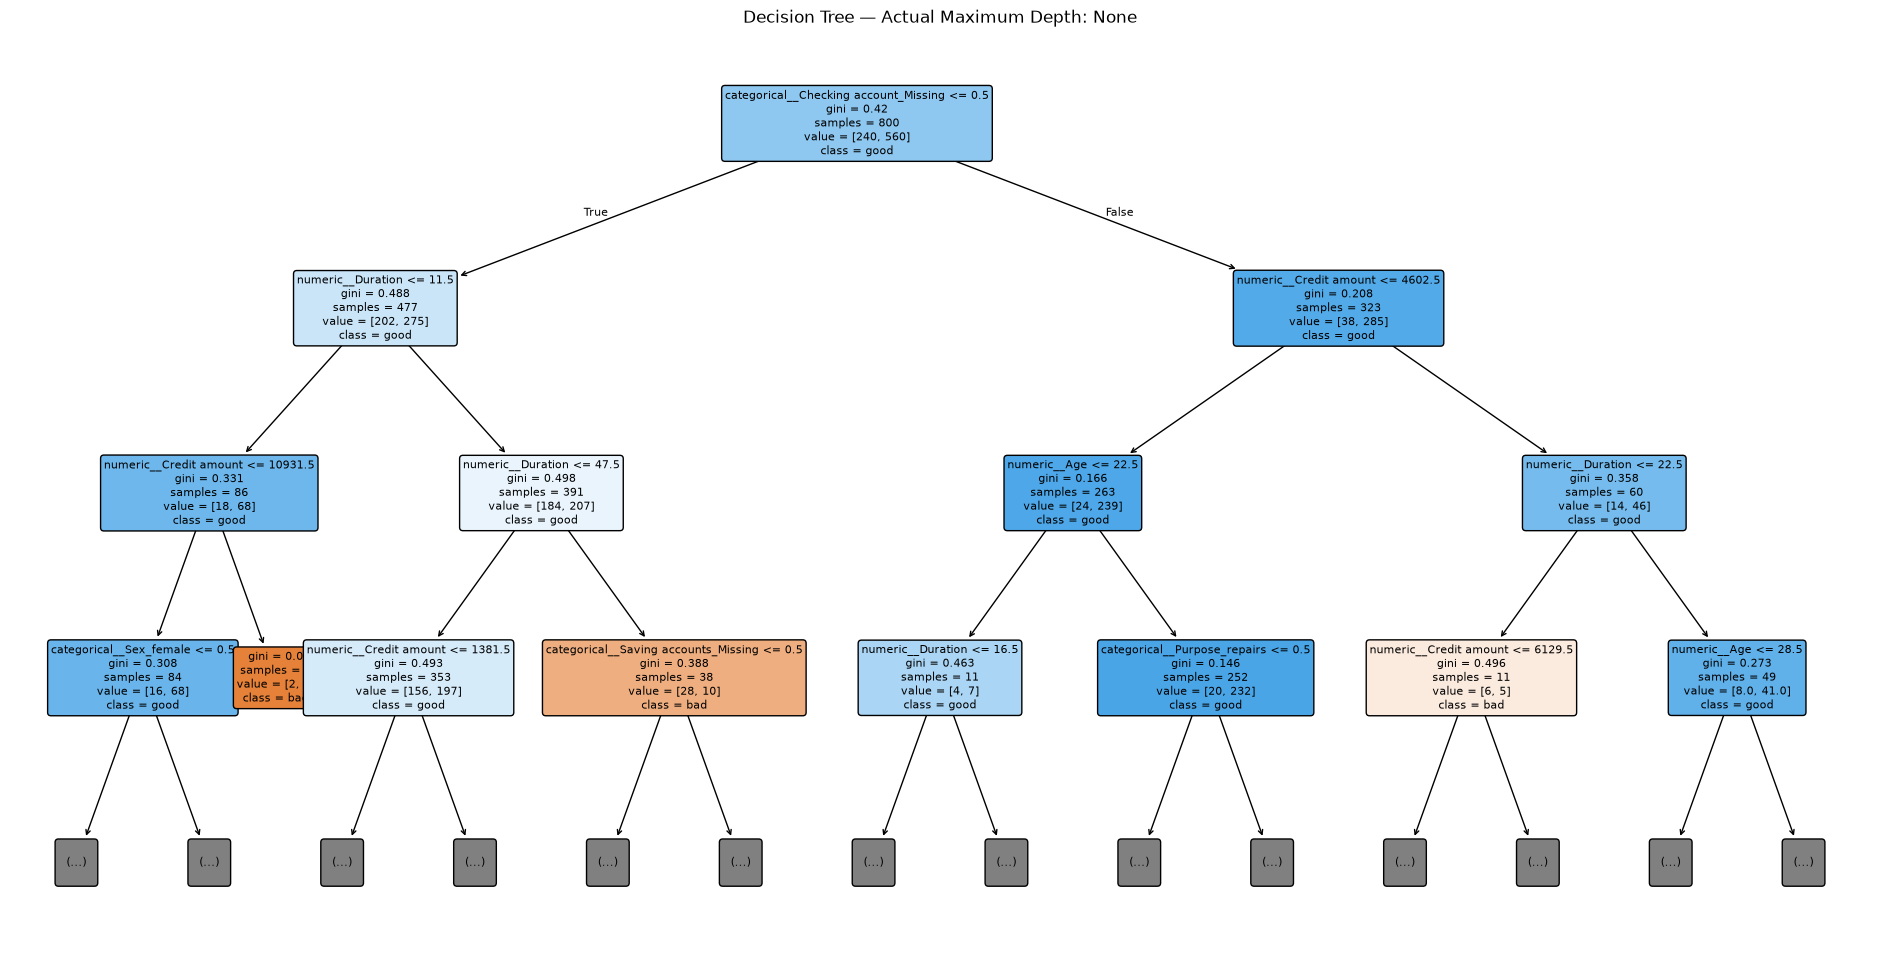

In [22]:
from IPython.display import display

for depth in depths:
    model = models[depth]

    feature_names = model.named_steps["preprocessor"].get_feature_names_out()
    class_names = model.named_steps["classifier"].classes_

    plt.figure(figsize=(24, 12))

    plot_tree(
        model.named_steps["classifier"],
        feature_names=feature_names,
        class_names=class_names,
        filled=True,
        rounded=True,
        max_depth=3,
        fontsize=8
    )

    plt.title(f"Decision Tree — Actual Maximum Depth: {depth}")
    plt.show()

In [23]:
for depth, model in models.items():
    tree_model = model.named_steps["classifier"]
    feature_names = model.named_steps["preprocessor"].get_feature_names_out()

    root_feature_index = tree_model.tree_.feature[0]
    root_threshold = tree_model.tree_.threshold[0]

    if root_feature_index >= 0:
        print(f"\nMax depth: {depth}")
        print("Root feature:", feature_names[root_feature_index])
        print("Root threshold:", round(root_threshold, 4))
        print(
            "Feature importance:",
            round(tree_model.feature_importances_[root_feature_index], 4)
        )


Max depth: 2
Root feature: categorical__Checking account_Missing
Root threshold: 0.5
Feature importance: 0.7565

Max depth: 4
Root feature: categorical__Checking account_Missing
Root threshold: 0.5
Feature importance: 0.4247

Max depth: 6
Root feature: categorical__Checking account_Missing
Root threshold: 0.5
Feature importance: 0.2638

Max depth: 10
Root feature: categorical__Checking account_Missing
Root threshold: 0.5
Feature importance: 0.1578

Max depth: None
Root feature: categorical__Checking account_Missing
Root threshold: 0.5
Feature importance: 0.1072


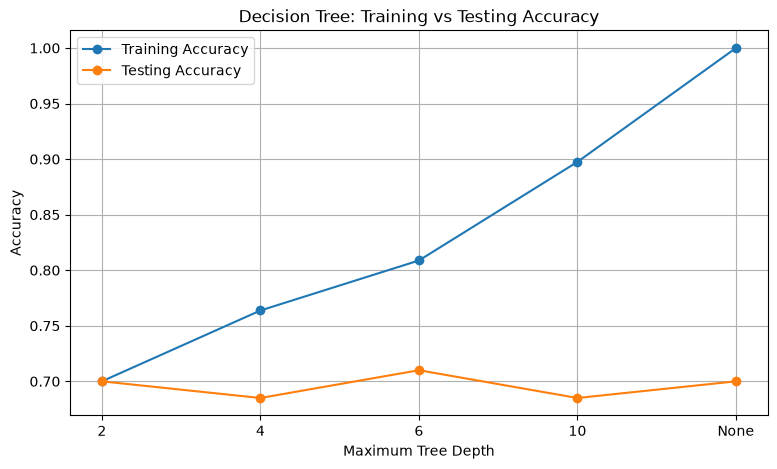

In [24]:
plt.figure(figsize=(9, 5))

plt.plot(
    results_df["Max Depth"],
    results_df["Training Accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    results_df["Max Depth"],
    results_df["Testing Accuracy"],
    marker="o",
    label="Testing Accuracy"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree: Training vs Testing Accuracy")
plt.legend()
plt.grid(True)
plt.show()